## <b>OpenDSS</b><br>
### <b>Roadmap 14:</b>  Hosting Capacity (HC) - Part 2

### <b>Objective:</b> 
The objective of the HC roadmap series  is to introduce the process of hosting capacity (HC).
You will apply the HC concepts to the IEEE 13 Node test feeder. 

#### <b>References:</b> <br>
DSS-Python: https://dss-extensions.org/DSS-Python/ and 
https://opendss.epri.com/opendss_documentation.html<br>

Hosting Capacity: Paper “A Comprehensive Review on Recent Developments of Hosting Capacity Estimation and Optimization for Active Distribution Networks”<br>

Python Tutorials: <br>
    Introdução à Computação com Python: um curso interativo:   
    https://panda.ime.usp.br/cc110/static/cc110/index.html<br>
    Matplotlib: https://matplotlib.org/<br>
    Pandas: https://pandas.pydata.org/


#### 1. Install libraries

In [1]:
!pip install numpy
!pip install pypiwin32
!pip install pandas
!pip install matplotlib
!pip install dss-python 

#### 2. Import libraries


In [2]:
import numpy as np    #np, mpl and pd serve as a nicknames
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import os
import dss #OpenDss Module

#### 3. Define the path where files are located

In [3]:
os.chdir('C:/Curso_OpenDSS/hosting_capacity')   # force going to the working folder (ADJUST FOR YOUR OWN PATH!)
mydir=os.getcwd()                          # mydir stores the working path
print(mydir)                               # just to check if things worked out

C:\Curso_OpenDSS\hosting_capacity


#### 4. Initialize OpenDSS via dss-python module

In [4]:
dss_engine = dss.DSS
DSSText = dss_engine.Text                                                      
DSSCircuit = dss_engine.ActiveCircuit                                            
DSSSolution = dss_engine.ActiveCircuit.Solution                                      
ControlQueue = dss_engine.ActiveCircuit.CtrlQueue   

#### 5. Compile master_IEEE13.dss file

Note that in in the dss file (IEEE13_loads.dss) , loads are not modeled for daily simulation.

In [5]:
DSSText.Command = 'Compile ' + mydir + '/master_IEEE13.dss'

<img style="float: middle;" src="diagrama_IEEE13.png" width="40%">


#### 6. List circuit elements

In [6]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:38
['Vsource.source', 'Transformer.substation', 'Transformer.xfm1', 'Transformer.regphasea', 'RegControl.regphasea', 'Transformer.regphaseb', 'RegControl.regphaseb', 'Transformer.regphasec', 'RegControl.regphasec', 'Capacitor.cap1', 'Capacitor.cap2', 'Load.671', 'Load.634a', 'Load.634b', 'Load.634c', 'Load.645', 'Load.646', 'Load.692', 'Load.675a', 'Load.675b', 'Load.675c', 'Load.611', 'Load.652', 'Load.670a', 'Load.670b', 'Load.670c', 'Line.650632', 'Line.632670', 'Line.670671', 'Line.671680', 'Line.632633', 'Line.632645', 'Line.645646', 'Line.692675', 'Line.671684', 'Line.684611', 'Line.684652', 'Line.671692']
List of Loads
Total:15
['671', '634a', '634b', '634c', '645', '646', '692', '675a', '675b', '675c', '611', '652', '670a', '670b', '670c']
List of Buses
Total:16
['sourcebus', '650', '633', '634', 'reg', '675', '611', '671', '645', '646', '692', '652', '670', '632', '680', '684']
List of Transformers
Total:5
['substation', 'xfm1', 'regphasea', 'regphaseb',

#### 7. Base Case - Loads with peak value : snapshot power flow, with no PV
This scenario considers all loads with its peak value.

In [7]:
#Configure power flow options
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=snapshot' 

DSSSolution.Solve()#Solve power flow

#### 7.1 Results - Base Case

In [8]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -3567.059 kW
Total kVAr delivered to the network: -1736.361 kvar
Total active losses: 112.108 kW
Percent losses: 3.143%
Total reactive losses: 327.706 kVAr


##### Unvervoltage and overvoltage are <font color='red'>planning limits</font>. 

<div class="alert alert-block alert-warning">
In OpenDSS, parameters normvminpu and normvmaxpu are options for the active circuit. These values default to <b>0.95 and 1.05</b>, respectively. The following commands, when present in the Master_LVNTS.dss file, change the default values:<br>
 . Set normvminpu=0.90<br>
 . Set normvmaxpu=1.10




##### Tranformer Amps loading and Line Amps loadins are <font color='red'> planning limits</font>
The AMPS loading is a metric used as <font color='red'>a planning limit for loadability</font> of a distribution feeder. These metrics can be used to determine the maximum level of accommodation of a specific energy resource. 

<font color='red'> Important remarks</font><br>
        . The Amps loading is being related to the amperes in the first winding. It consists in dividing the current by the base to get per unit. The NormAmps property gives the normal ampere rating (base current) for PD elements (power delivery elements, like transformers). In OpenDSS, for transformers, NormAmps is defined for Winding 1, which is usually the HV for a 2-winding transformer (in this test system, all transformers are 2-winding). This is usually not a problem for a 2-winding transformer since the % overload should be the same for either winding (but it could be an issue for transformers with 3 or more windings).
        . If the transformer is delta/wye and the load is unbalanced, it is necessary to be careful which current from openDSS to use. Normally, when one asks for the current, one gets the line current. But the rating (NormAmps) is being rated on the Delta winding, so it is mandatory to get the winding current or use the wye winding for the base. For most distribution planning problems, knowing the overload in the HV winding is generally adequate.
        . The winding currents can be obtained through the DSSCircuit.Transformers.WdgCurrents, which gives the currents in the complex form; or by dividing the line currents obtained from DSSCircuit.ActiveElement.CurrentsMagAng by sqrt(3). 


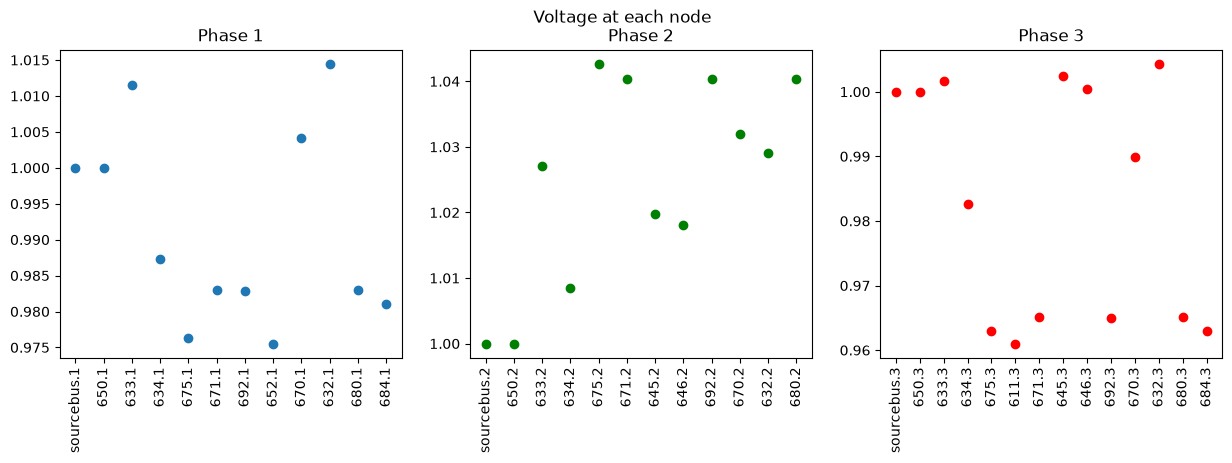

In [9]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

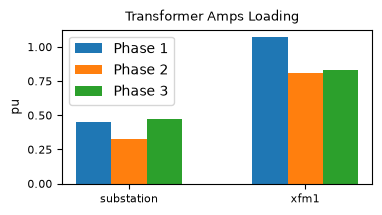

In [10]:
# Transformers AMPS loading 
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

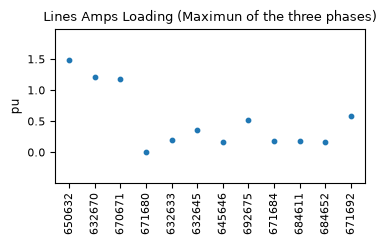

In [11]:
#**************--------------Lines Amps Loading
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()

#Instalar pv no snapshot

In [ ]:
#Just to check what the function returns
#DSSCircuit.SetActiveElement('line.650632')
#max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#DSSCircuit.ActiveElement.NormalAmps

#### 8. Scenario 1 - Loads with 20% of peak value : snapshot power flow, with no PV
In this scenario, the load must be adjusted to 20% of the peak load. To adjust the load for this condition, you can use the command 'set loadmult'.

#####  <font color='red'> Homework: For Scenario 8 you must obtaing the following results: powers, voltages in all the nodes, lines amps loading and transformers amps loading.</font>

In [12]:
#Configure power flow options
DSSText.Command = 'set loadmult = 0.2'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=snapshot' 

DSSSolution.Solve() #Solve power flow

#### 9. Scenario 2 - Loads with 20% of peak value and PV generation

##### <font color='red'> Homework: 

<font color='red'>In this scenario, the load must be adjusted to 20% of the peak load and PV generation must be installed in Buses 633, 675 e 680. Generation will be increased gradually and the limiting metrics will be analysed. 
Limiting metrics and acceptable limits:<br>
. Overvoltage: 1,05 pu<br>
. Line Amps loading: 100% (1 pu)<br>
. Transformer Amps loading: 100% (1 pu)<br>
Run a power flow for each level of generation, starting with 50kW. Each new power flow calculation should consider the generation increased by 100 kW. The KVA parameter must be adjusted accordingly.<br><br>
Check which metric limits the penetration of the photovoltaic generation.. </font>

In [13]:
#Load the circuit model
DSSText.Command = 'Compile ' + mydir + '/master_IEEE13.dss'

#Get list of elements
Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#Define curves fo the PV System: Temperature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYCurve.TempxP npts=4 xarray=[0 25 75 100] yarray=[1.2 1.0 0.8 0.6]'
DSSText.Command = 'New XYCurve.PxEff npts=4 xarray=[.1 .2 .4 1.0] yarray=[.86 .9 .93 1]'

#Install the PV System (no transformer will be used to connect the system to the bus)
DSSText.Command = 'New PVSystem.PV_633 phases=3 conn=wye bus=633 kV=4.16 kVA=50 Pmpp=50 temperature=25 effcurve=PxEff P-TCurve=TempxP vmaxpu=2 vminpu=0.5 pf=1'

#Configure power flow options
DSSText.Command = 'set loadmult = 0.2'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=snapshot' 

DSSSolution.Solve()

#### 10. Scenario 2: daily simulation, with no PV

In [14]:
DSSText.Command = 'Compile ' + mydir + '/master_IEEE13.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

#### 10.1 Prepare the loads to perform daily simulation

In [15]:
ind_loads=['Load.671', 'Load.646']#list of undustrial load, all others are residential

#load the residential profile file
# Initialize an empty list to store the values
resd_profile = []
#read the file
with open(mydir + '/resd_profile.csv', 'r') as file:
    for line in file:
        # Convert each line to a float and append it to the list
        resd_profile.append(float(line.strip()))

#load the industrial profile file
# Initialize an empty list to store the values
ind_profile = []
#read the file
with open(mydir + '/ind_profile.csv', 'r') as file:
    for line in file:
        # Convert each line to a float and append it to the list
        ind_profile.append(float(line.strip()))

#Create the loadshapes objetcs
#residential
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

#industrial
DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

#Assign loadshape to load
for iload, load in enumerate (Loadnames):
    DSSCircuit.SetActiveElement('load.%s' %(load))
    if load in ind_loads:#industrial
        DSSCircuit.ActiveElement.Properties('daily').Val = str('ind_loadshape')
    else:#residential
        DSSCircuit.ActiveElement.Properties('daily').Val = str('resd_loadshape')

#### 10.2 Run power flow hour by hour while retrieving data

In [16]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily' 
DSSText.Command = 'set stepsize=1h' 
DSSText.Command = 'set number=1' # this means that the Solve command will solve the power flow for one hour only, whenever it is called.

nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 3

# Inicialize variables to retrieve network data,
Total_Act_Power = [0 for i in range(24)]
Total_React_Power = [0 for i in range(24)]
Total_Act_Losses = [0 for i in range(24)]
Total_React_Losses = [0 for i in range(24)]
busVpuA_SC1=[0 for i in range(24)]
busVpuB_SC1=[0 for i in range(24)]
busVpuC_SC1=[0 for i in range(24)]
All_Wdg_Amp = np.zeros((len(onlytrafo),24,24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Load_kW = np.zeros((len(Loadnames),24))#active power for each load
Load_kvar = np.zeros((len(Loadnames),24))#reactive power for each load
Line_Max_Amp = np.zeros((len(Linenames),24)) 

#Solve power flow hour by hour; retrieve data (voltage and trafos current) at each step
for h in range(24): #iterates throught 24 hours (1 to 24)
    
    DSSSolution.Solve() # solve power flow for the specific hour

    #Power injected and losses
    Total_Act_Power[h] = DSSCircuit.TotalPower[0] #in kW
    Total_React_Power[h] = DSSCircuit.TotalPower[1] #in kVAr
    Total_Act_Losses[h] = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
    Total_React_Losses[h] = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr

    #Voltage
    busVpuA_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
    busVpuB_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
    busVpuC_SC1[h]=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3

    #Transformer winding current
    for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.Transformers.Name = trafo
          All_Wdg_Amp[itrafo,h,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
           

    #*********Load Power
    for iload, load in enumerate(Loadnames):
    #TotalPowers returns a double array with the total powers (kW and kvar) at ALL terminals of the active circuit element.
    #load has only one terminal
          DSSCircuit.SetActiveElement('load.%s' %(load))
          Load_kW[iload,h] = DSSCircuit.ActiveElement.TotalPowers[0]
          Load_kvar[iload,h] = DSSCircuit.ActiveElement.TotalPowers[1]
   
    #**********Maximun line  current
    for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        Line_Max_Amp[iline,h] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
        
       

In [ ]:
#DSSCircuit.Transformers.Name = 'xfm1'
#DSSCircuit.Transformers.WdgCurrents

#### 10.3. Results - Scenario 2

In [17]:
#-------Results for Energy
# Circuit kWh and Losses kWh
kWh_SC1 = np.sum(Total_Act_Power)
kVArh_SC1 = np.sum(Total_React_Power)
kWh_Loss_SC1 = np.sum(Total_Act_Losses) 
kVArh_Loss_SC1 = np.sum(Total_React_Losses)

print("Total kWh delivered to the network: %.3f kW" %kWh_SC1)
print("Total kVAr delivered to the network: %.3f kvar" %kVArh_SC1)
print("Total active losses: %.3f kW" %kWh_Loss_SC1)
print("Percent losses: %.3f" %abs(((kWh_Loss_SC1/kWh_SC1)*100)) + "%")
print("Total reactive losses %.3f kVAr" %kVArh_Loss_SC1)

Total kWh delivered to the network: -85981.089 kW
Total kVAr delivered to the network: -42581.732 kvar
Total active losses: 3073.106 kW
Percent losses: 3.574%
Total reactive losses 8991.735 kVAr


In [19]:
#------Results for Voltage
#get node names
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#nodes in phase 1
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#nodes in phase 2
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#nodes in phase 3

#Each dataframes will have 24 rows and a column for voltages of each node
dfbusVpuA_SC1 = pd.DataFrame(np.row_stack(busVpuA_SC1),columns=nodesA)
dfbusVpuB_SC1 = pd.DataFrame(np.row_stack(busVpuB_SC1),columns=nodesB)
dfbusVpuC_SC1 = pd.DataFrame(np.row_stack(busVpuC_SC1),columns=nodesC)

# Drop dataframe columns related to the voltage regulators
columns_to_drop = [col for col in dfbusVpuA_SC1.columns if col.startswith('reg')]
dfbusVpuA_SC1 = dfbusVpuA_SC1.drop(columns=columns_to_drop, axis=1)

columns_to_drop = [col for col in dfbusVpuB_SC1.columns if col.startswith('reg')]
dfbusVpuB_SC1 = dfbusVpuB_SC1.drop(columns=columns_to_drop, axis=1)

columns_to_drop = [col for col in dfbusVpuC_SC1.columns if col.startswith('reg')]
dfbusVpuC_SC1 = dfbusVpuC_SC1.drop(columns=columns_to_drop, axis=1)

#plots

ax = dfbusVpuA_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuB_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfbusVpuC_SC1.plot(figsize=(6,3))
plt.title('Voltage at all nodes - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()


C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\1289335101.py:8: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfbusVpuA_SC1 = pd.DataFrame(np.row_stack(busVpuA_SC1),columns=nodesA)
C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\1289335101.py:9: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfbusVpuB_SC1 = pd.DataFrame(np.row_stack(busVpuB_SC1),columns=nodesB)
C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\1289335101.py:10: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfbusVpuC_SC1 = pd.DataFrame(np.row_stack(busVpuC_SC1),columns=nodesC)


ValueError: Cannot specify both 'axis' and 'index'/'columns'

C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\1681586747.py:23: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.row_stack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\1681586747.py:24: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.row_stack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\1681586747.py:25: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.row_stack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)
C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\1681586747.py:27: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.row_stack(Max_Transf_Amps[:,:].T),columns=onlytrafo)


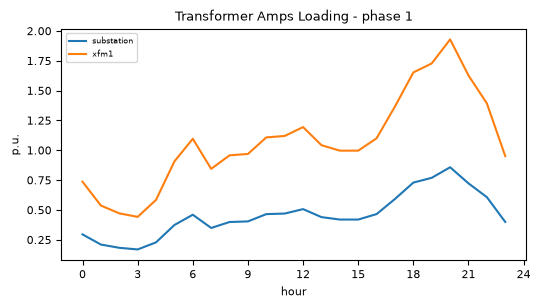

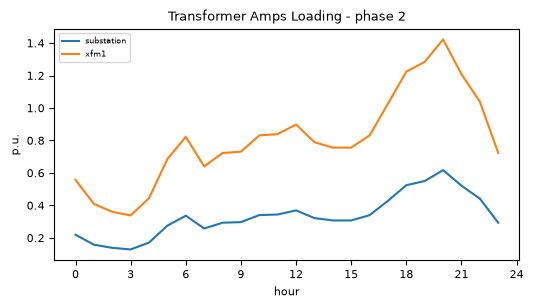

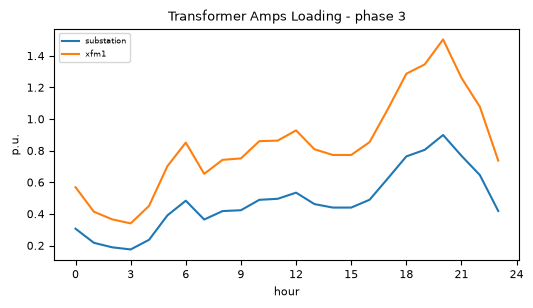

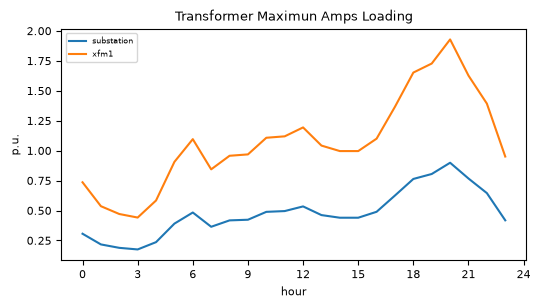

In [20]:
#-----Results for Amps Loading at each phase in pu for each transformer
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),24,3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),24,3))#to store all phases Amps loading at HV side 
#Transf_Max_Amps_loading = np.zeros((len(onlytrafo),24))#to store maximun amps loading at HV side (the maximun of the three phases)       
#amp_rate=[0 for i in range(len(onlytrafo))]

#calculate Amps loading at each phase in pu for each transformer
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          Transf_Wdg1_Amps[itrafo,:,0]=(np.sqrt(All_Wdg_Amp[itrafo,:,0]**2+All_Wdg_Amp[itrafo,:,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,:,1]=(np.sqrt(All_Wdg_Amp[itrafo,:,8]**2+All_Wdg_Amp[itrafo,:,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,:,2]=(np.sqrt(All_Wdg_Amp[itrafo,:,16]**2+All_Wdg_Amp[itrafo,:,17]**2))#HV side Wdg current , phase 3

          Transf_Amps_loading[itrafo,:,0]=Transf_Wdg1_Amps[itrafo,:,0]/amp_rate #HV side Amps loading, phase 1 
          Transf_Amps_loading[itrafo,:,1]=Transf_Wdg1_Amps[itrafo,:,1]/amp_rate #HV side Amps loading, phase 2
          Transf_Amps_loading[itrafo,:,2]=Transf_Wdg1_Amps[itrafo,:,2]/amp_rate #HV side Amps loading, phase 3

#*********For each transformer, at each hour, get the maximun loading of the three phases
Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)

#Each dataframe has 24 rows and a column for Amps loading of each transformer
dfAmpsTrafo_phA_SC1 = pd.DataFrame(np.row_stack(Transf_Amps_loading[:,:,0].T),columns=onlytrafo)
dfAmpsTrafo_phB_SC1 = pd.DataFrame(np.row_stack(Transf_Amps_loading[:,:,1].T),columns=onlytrafo)
dfAmpsTrafo_phC_SC1 = pd.DataFrame(np.row_stack(Transf_Amps_loading[:,:,2].T),columns=onlytrafo)

dfAmpsTrafo_Max_SC1 = pd.DataFrame(np.row_stack(Max_Transf_Amps[:,:].T),columns=onlytrafo)

#plots
ax = dfAmpsTrafo_phA_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 1',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phB_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 2',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_phC_SC1.plot(figsize=(6,3))
plt.title('Transformer Amps Loading - phase 3',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfAmpsTrafo_Max_SC1.plot(figsize=(6,3))
plt.title('Transformer Maximun Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("p.u.",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:

#display(All_Wdg_Amp[1,:,:])
#display(All_Wdg_Amp[1,:,0])
#display(Transf_Amps_loading[:,:,0])
#display((Transf_Amps_loading[:,:,1]))
#display(dfAmpsTrafo_phA_SC1)

C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\2981892782.py:3: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfLoad_kW = pd.DataFrame(np.row_stack(Load_kW[:,:].T),columns=Loadnames)
C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\2981892782.py:4: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfLoad_kvar = pd.DataFrame(np.row_stack(Load_kvar[:,:].T),columns=Loadnames)


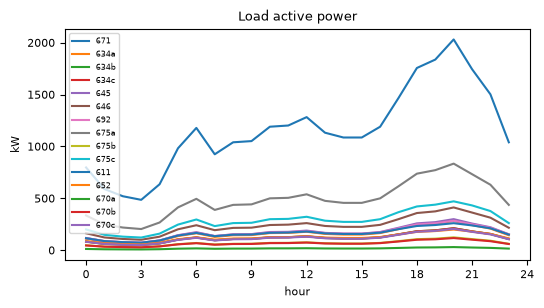

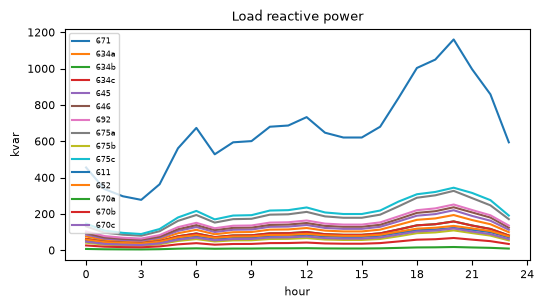

In [21]:
#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.row_stack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.row_stack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

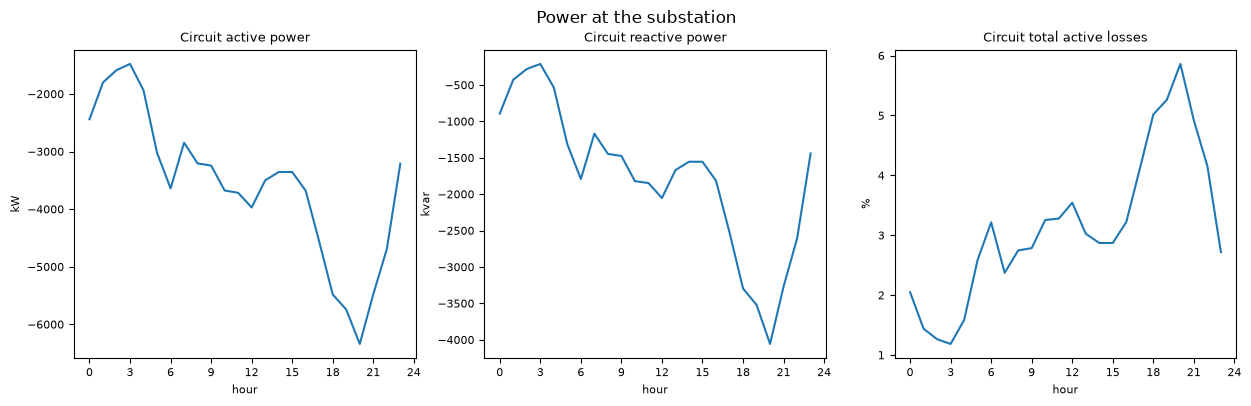

In [22]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#DSSCircuit.SetActiveElement('line.632645')
#display(DSSCircuit.ActiveElement.Name)
#display(DSSCircuit.ActiveElement.CurrentsMagAng)
#display(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])
#display(max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2]))

In [ ]:
#Max_Transf_Amps = np.max(Transf_Amps_loading, axis=2)
#display(Max_Transf_Amps)
#display(Transf_Amps_loading)

C:\Users\edelo\AppData\Local\Temp\ipykernel_89656\2401799903.py:9: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  dfLine_Max_Amp = pd.DataFrame(np.row_stack(Line_Max_Loading[:,:].T),columns=Linenames)


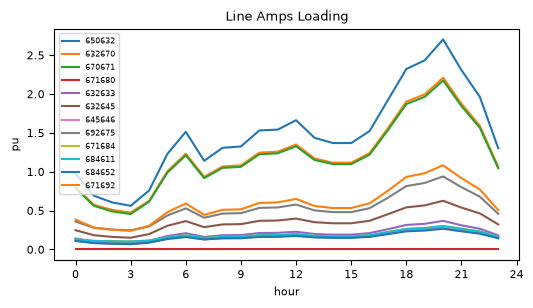

In [23]:
#*******---------Results for Line Amps Loading

Line_Max_Loading = np.zeros((len(Linenames),24))
for iline, line in enumerate(Linenames):
    DSSCircuit.SetActiveElement('Line.%s' %(line))
    amp_rate = DSSCircuit.ActiveElement.NormalAmps
    Line_Max_Loading[iline,:] = Line_Max_Amp[iline,:]/amp_rate

dfLine_Max_Amp = pd.DataFrame(np.row_stack(Line_Max_Loading[:,:].T),columns=Linenames)

#plots
ax = dfLine_Max_Amp.plot(figsize=(6,3))
plt.title('Line Amps Loading',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("pu",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()